# Toy task: an agent that already knows the task states
Oct 2026 \
author: Inês Laranjeira (sketch drafted with Claude)

The simplest case: an actor-critic agent that is **given the task structure from the start (M1)**.
It sees the stimulus, and when there is no stimulus it has two clocks: time since feedback and time
since its last movement. Question: does it learn the task, and how many trials does it need?

Caveat: this is a **toy** task, much easier than the real one. It has one contrast, responses
register as soon as a movement starts (no wheel threshold), bouts have a fixed length, and there
is no motor noise. The code is in `toy_task.py`; the notebook uses only `model='M1'`.

## Timesteps and actions
* **Timestep** = 100 ms bin.
* **Actions**, at every bin where the agent is still: **wait**, **start a left bout**, **start a right bout**.
  A bout lasts 3 bins (300 ms) and the agent makes no decisions during it.
* **Task epochs**:
  * **ITI**: 10 bins after feedback. Moving is free.
  * **Quiescence**: the agent must stay still for 4-7 bins. A movement restarts the count.
  * **Stimulus**: the first bout is the response. The correct side gives reward 1, the wrong side 0.
    40 bins without moving is a timeout.
* **What the agent sees (its state)**: stimulus left or right; otherwise (time since feedback, time
  since last movement), each coded as a tapped delay line (one feature per bin value).
* **Learning**, at each decision point, with k = bins until the next decision:
  * TD error: δ = R + γᵏ·V(s′) − V(s)
  * Critic: V(s) += α·δ
  * Actor: the preference for the chosen action moves by β·δ (softmax policy gradient), and
    preferences relax slowly toward a baseline movement rate (about 0.18 onsets per bin at the start).

In [1]:
import numpy as np, pandas as pd, glob
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import toy_task as tt

COL = '#eb6834'          # M1
INK, MUTED = '#1d1d1b', '#6b6b66'
EPOCH_COL = ['#efefed', '#d6d6d2', '#b4b4ae']   # ITI, quiescence, stimulus
EPOCH_NAME = ['ITI', 'quiescence', 'stimulus']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'font.size': 10, 'axes.titlesize': 11, 'lines.linewidth': 2})
SEEDS, N_TRIALS = range(10), 3000

## What the agent does, bin by bin
Each strip shows 20 s of behaviour from the same simulated agent: its first trials, after 300
trials, and after 1500 trials. The shading is the task epoch. Ticks above the midline are left-bout
onsets and ticks below are right-bout onsets. Thick coloured ticks are responses; ✓ and ✗ mark
correct and wrong.

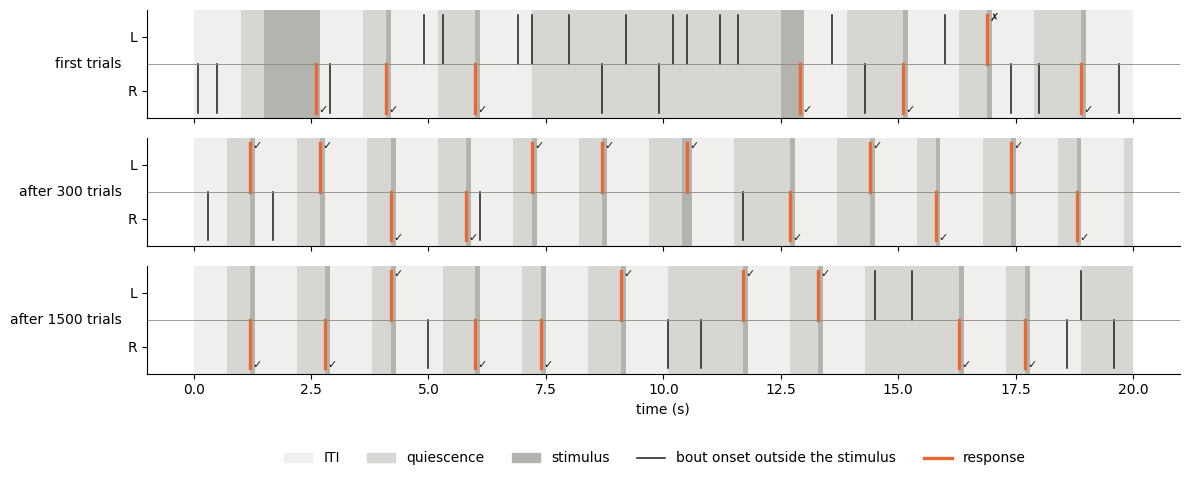

In [2]:
stages = [(0, 'first trials'), (300, 'after 300 trials'), (1500, 'after 1500 trials')]
fig, axes = plt.subplots(len(stages), 1, figsize=(12, 4.6), sharex=True)
W = 200
for ax, (lo, title) in zip(axes, stages):
    _, _, tr = tt.run('M1', n_trials=lo + 40, seed=1, record=(lo, lo + 40))
    tr = tr[:W]; ax.grid(False)
    for i, ph in enumerate(tr[:, 1].astype(int)):
        ax.axvspan(i * tt.DT, (i + 1) * tt.DT, color=EPOCH_COL[ph], lw=0)
    for i in np.flatnonzero(tr[:, 2] > 0):
        a, resp = int(tr[i, 2]), tr[i, 1] == 2
        y0, y1 = (0.5, 0.95) if a == 1 else (0.05, 0.5)
        ax.plot([i * tt.DT] * 2, [y0, y1], color=COL if resp else INK, lw=2.4 if resp else 1.1)
        if resp:
            ax.text(i * tt.DT + 0.05, 0.97 if a == 1 else 0.03, '✓' if tr[i, 4] > 0 else '✗',
                    fontsize=8, color=INK, va='top' if a == 1 else 'bottom')
    ax.axhline(0.5, color='#8a8a85', lw=0.6)
    ax.set_yticks([0.25, 0.75]); ax.set_yticklabels(['R', 'L']); ax.set_ylim(0, 1)
    ax.set_ylabel(title, rotation=0, ha='right', va='center')
axes[-1].set_xlabel('time (s)')
handles = [Patch(color=EPOCH_COL[i], label=EPOCH_NAME[i]) for i in range(3)] + \
          [Line2D([], [], color=INK, lw=1.1, label='bout onset outside the stimulus'),
           Line2D([], [], color=COL, lw=2.4, label='response')]
fig.legend(handles=handles, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.55, -0.05))
fig.tight_layout(rect=(0, 0.05, 1, 1))

## Learning curves (10 seeds, default learning rate α = β = 0.05)

/var/folders/nt/d2j3zp9d1xzb8wgfrw81j0c40000gn/T/ipykernel_16581/4172703193.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ttc = df.groupby('seed').apply(lambda g: tt.trials_to_criterion(g.accuracy.values, g.trial.values))


trials to 80% correct (two consecutive blocks): {'min': 50.0, '50%': 50.0, 'max': 100.0}


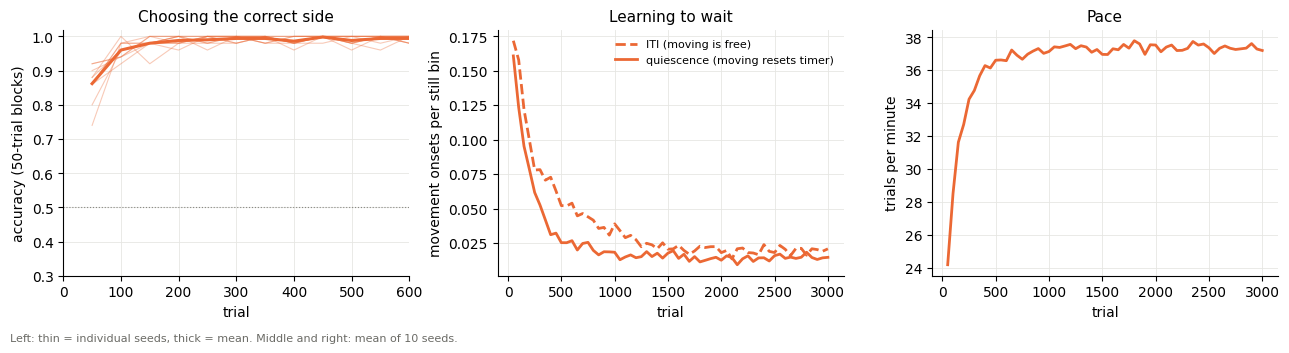

In [3]:
rows = []
for s in SEEDS:
    rows += tt.run('M1', n_trials=N_TRIALS, seed=s)[0]
df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
ax = axes[0]
for s, g in df.groupby('seed'):
    ax.plot(g.trial, g.accuracy, color=COL, lw=0.8, alpha=0.35)
m = df.groupby('trial').accuracy.mean()
ax.plot(m.index, m.values, color=COL, lw=2.2)
ax.axhline(0.5, color='#8a8a85', lw=0.8, ls=':')
ax.set_xlim(0, 600); ax.set_ylim(0.3, 1.02)
ax.set_xlabel('trial'); ax.set_ylabel('accuracy (50-trial blocks)'); ax.set_title('Choosing the correct side')

ax = axes[1]
d = df.groupby('trial')[['move_iti', 'move_quiescence']].mean()
ax.plot(d.index, d.move_iti, color=COL, ls='--', label='ITI (moving is free)')
ax.plot(d.index, d.move_quiescence, color=COL, label='quiescence (moving resets timer)')
ax.set_xlabel('trial'); ax.set_ylabel('movement onsets per still bin')
ax.set_title('Learning to wait'); ax.legend(frameon=False, fontsize=8)

ax = axes[2]
d = df.groupby('trial').trials_per_min.mean()
ax.plot(d.index, d.values, color=COL)
ax.set_xlabel('trial'); ax.set_ylabel('trials per minute'); ax.set_title('Pace')
fig.text(0.01, -0.02, 'Left: thin = individual seeds, thick = mean. Middle and right: mean of 10 seeds.',
         fontsize=8, color=MUTED)
fig.tight_layout()

ttc = df.groupby('seed').apply(lambda g: tt.trials_to_criterion(g.accuracy.values, g.trial.values))
print('trials to 80% correct (two consecutive blocks):', ttc.describe()[['min', '50%', 'max']].to_dict())

## How many trials, across learning rates, compared with mice?
The learning rate sweep uses α = β. Real mice: number of `trainingChoiceWorld` trials per mouse in the
local training files (`paper-individuality/data/training/training_data`).

M1 median trials to 80% by learning rate: {0.002: 400.0, 0.005: 150.0, 0.01: 100.0, 0.02: 100.0, 0.05: 50.0, 0.1: 50.0}
runs that never reached 80% within 3000 trials: {0.002: 0, 0.005: 0, 0.01: 0, 0.02: 0, 0.05: 0, 0.1: 0}
       n_trials  n_sessions
count     102.0       102.0
25%      5836.0        11.0
50%      9575.0        16.0
75%     15542.0        25.0


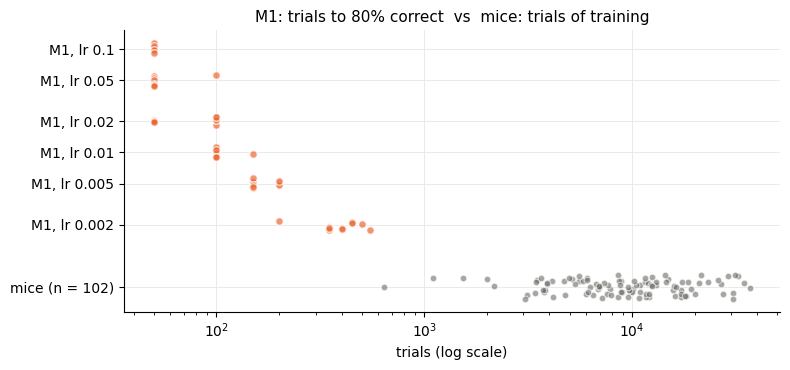

In [4]:
rows = []
for lr in [0.002, 0.005, 0.01, 0.02, 0.05, 0.1]:
    for s in SEEDS:
        b = pd.DataFrame(tt.run('M1', n_trials=N_TRIALS, seed=s, alpha=lr, beta=lr)[0])
        rows.append(dict(lr=lr, seed=s, ttc=tt.trials_to_criterion(b.accuracy.values, b.trial.values)))
lr_df = pd.DataFrame(rows)

mice = []
for f in glob.glob('../paper-individuality/data/training/training_data/training_data_trials_*'):
    d = pd.read_parquet(f, columns=['session', 'task_protocol'])
    d = d[d.task_protocol.str.contains('training', na=False)]
    mice.append(dict(mouse=f.split('trials_')[-1], n_trials=len(d), n_sessions=d.session.nunique()))
mice = pd.DataFrame(mice)

fig, ax = plt.subplots(figsize=(8, 3.8))
y_m1 = np.log10(lr_df.lr) + np.random.default_rng(2).uniform(-0.06, 0.06, len(lr_df))
ax.scatter(lr_df.ttc, y_m1, s=30, color=COL, alpha=0.7, edgecolor='white', linewidth=1)
ax.scatter(mice.n_trials, np.full(len(mice), -3.3) + np.random.default_rng(3).uniform(-0.12, 0.12, len(mice)),
           s=22, color=MUTED, alpha=0.6, edgecolor='white', linewidth=0.8)
ax.set_xscale('log')
ax.set_yticks(list(np.log10(sorted(lr_df.lr.unique()))) + [-3.3])
ax.set_yticklabels([f'M1, lr {v:g}' for v in sorted(lr_df.lr.unique())] + [f'mice (n = {len(mice)})'])
ax.set_xlabel('trials (log scale)')
ax.set_title('M1: trials to 80% correct  vs  mice: trials of training')
fig.tight_layout()
print('M1 median trials to 80% by learning rate:', lr_df.groupby('lr').ttc.median().to_dict())
print('runs that never reached 80% within', N_TRIALS, 'trials:', lr_df.ttc.isna().groupby(lr_df.lr).sum().to_dict())
print(mice[['n_trials', 'n_sessions']].describe().loc[['count', '25%', '50%', '75%']].round(0))

## Observations
* **The agent that knows the task states learns almost immediately.** At the default learning rate it
  is already about 85% correct in the first 50 trials and reaches 80% correct (two consecutive
  50-trial blocks) in 50–100 trials across all 10 seeds.
* **Waiting takes longer than choosing.** Movement during quiescence drops over about 500 trials,
  and the pace rises from about 24 to 37 trials per minute.
* **ITI movement falls too, although it is free.** The fall is only slightly slower than in
  quiescence. So "suppresses only where moving is costly" is not a clean signature of knowing the
  structure in this toy: the learning rule also drifts toward waiting in general. This weakens the
  selective-vs-global suppression test proposed in the spec.
* **About 100× faster than mice.** Even at the lowest learning rate tried (0.002), M1 needs only
  about 400 trials. The 102 mice in the local training files ran a median of about 9,600
  `trainingChoiceWorld` trials (IQR 5,800–15,500) over a median of 16 sessions.
* **How to read that gap.** The toy is far easier than the real task, and a fitted model could match
  the mice by taking a much smaller learning rate. Raw trial counts therefore can't decide the
  question. What could is the *shape* of learning: a small learning rate predicts slow, smooth
  improvement, while slow learning that comes from having to discover states predicts plateaus
  followed by jumps.
* **Next step for this notebook:** make the task more realistic (contrast levels, a wheel threshold
  for responses) and check whether M1 still learns this fast.